# 09 · cuRobo로 Franka 계획하기 — 실제 라이브러리 들여다보기

> 08에서 2관절 팔로 직접 만든 것(FK, 충돌 구, η 비용, MPPI)을 cuRobo는 7관절 Franka에 대해 GPU로 한다. 배열 모양과 비용 항을 직접 꺼내 보면 같은 구조라는 것을 확인할 수 있다.

**지금 위치**

01~04 기초·MPC → 05~07 MPPI → 08 로봇팔 → **09 cuRobo Franka** → 10 지도 → 11 손 비용 → 12 결과 → 13 Isaac Sim

**이 노트를 끝내면**
1. cuRobo에서 Franka의 FK와 충돌 구(활성 61개)를 직접 계산하고, buffer가 반지름을 어떻게 바꾸는지 설명할 수 있다.
2. horizon을 **가변 dt**로 나누는 이유를 말하고, 0.75 s와 0.675 s가 어떻게 나오는지 계산할 수 있다.
3. Isaac Sim 없이 cuRobo MPC를 한 번 풀고, 후보 400개의 `[400, 30, 7] → [400, 30]` 흐름과 비용 항을 해석할 수 있다.

**필요한 것:** 08의 FK·충돌 구·η 비용, 05~07의 MPPI · **실행 환경:** cuRobo + CUDA GPU ("Isaac Sim 4.5 + cuRobo" 커널). 없으면 cuRobo 셀은 건너뛴다. · **예상 시간:** 40분

## 복습 퀴즈 (08)

<details><summary>1. 순기구학(FK)은 무엇에서 무엇을 계산하나?</summary>

관절 각도에서 각 링크와 손끝의 위치를 계산한다. 링크마다 길이 × (cos, sin)을 이어 붙인다.
</details>

<details><summary>2. 로봇팔 모양을 충돌 구로 근사하는 이유는?</summary>

구와 장애물 사이 간격은 "중심 거리 − 반지름들"로 아주 빠르게 계산된다. 후보 수백 개 × 시점 수십 개를 GPU로 한 번에 검사할 수 있다.
</details>

<details><summary>3. η 비용에서 겹친 뒤(간격 < 0)의 기울기는 η에 따라 달라지나?</summary>

달라지지 않는다. 겹친 뒤에는 항상 −w로 같은 기울기다. η가 바꾸는 것은 비용이 켜지는 거리와 η 안쪽의 크기다.
</details>

## 0. cuRobo란

**cuRobo**는 NVIDIA가 만든 GPU 기반 로봇 모션 라이브러리다. 08에서 numpy로 한 일을 CUDA로 한다. FK, 충돌 구 거리, 비용 계산, MPPI 샘플링을 모두 GPU에서 처리한다. 이 프로젝트는 그중 MPPI 기반 MPC인 `MpcSolver`를 쓴다.

아래 셀은 cuRobo와 GPU를 쓸 수 있는지 확인한다. 이후 cuRobo 셀은 `HAS_CUROBO`가 False면 건너뛴다.

In [1]:
import json, time
from collections import Counter
import numpy as np
from common import setup_plot, dt_array, read_jsonl, load_yaml, REPO, EVIDENCE, CUROBO
plt = setup_plot()
try:
    import torch
    import curobo
    HAS_CUROBO = torch.cuda.is_available()
except ImportError:
    HAS_CUROBO = False
print('cuRobo + CUDA 사용 가능:', HAS_CUROBO)

cuRobo + CUDA 사용 가능: True


## 1. 7관절 Franka의 FK와 충돌 구

### 문제
08의 팔은 관절 2개, 구 8개였다. 실제 Franka는 관절 7개에 손(그리퍼)까지 달려 있다. 구는 몇 개이고 어디에 붙어 있을까?

### 아이디어
cuRobo는 로봇 설정 파일(`franka.yml`)에 링크별 충돌 구 목록을 갖고 있다. 관절 각도를 넣으면 FK로 모든 구의 중심을 계산해 준다. 08의 `sphere_centers`가 하던 일이다.

아래 셀은 Franka의 기본 자세(retract 자세)에서 구를 계산한다. buffer를 기본값 0.004 m로 둔 모델과, 이 프로젝트처럼 0.02 m로 둔 모델을 함께 만들어 비교한다.
- 반환 배열에는 구가 **65칸** 있다. 그중 반지름이 0 이하인 칸은 쓰지 않는 빈자리(물체를 잡았을 때 쓰는 자리 등)다.
- 그래서 실제로 쓰는 **활성 구는 61개**다.

In [2]:
if HAS_CUROBO:
    from curobo.cuda_robot_model.cuda_robot_model import CudaRobotModel, CudaRobotModelConfig
    from curobo.types.base import TensorDeviceType
    from curobo.util_file import load_yaml as cu_load_yaml, join_path, get_robot_configs_path
    ta = TensorDeviceType()

    def franka_model(buffer):
        cfg = cu_load_yaml(join_path(get_robot_configs_path(), 'franka.yml'))['robot_cfg']
        cfg['kinematics']['collision_sphere_buffer'] = buffer
        return CudaRobotModel(CudaRobotModelConfig.from_data_dict(cfg['kinematics'], tensor_args=ta)), cfg

    km20, rcfg = franka_model(0.02)       # 이 프로젝트 설정
    km04, _ = franka_model(0.004)         # cuRobo 기본값
    q_ret = ta.to_device([rcfg['kinematics']['cspace']['retract_config'][:7]])
    print('관절 이름:', rcfg['kinematics']['cspace']['joint_names'][:7])
    print('retract 자세 [rad]:', np.round(q_ret.cpu().numpy()[0], 2))

    state = km20.get_state(q_ret)                       # FK 한 번
    sph20 = state.link_spheres_tensor.reshape(-1, 4).cpu().numpy()
    sph04 = km04.get_state(q_ret).link_spheres_tensor.reshape(-1, 4).cpu().numpy()
    active = sph20[:, 3] > 0
    print('손끝(EE) 위치 [m]:', state.ee_position.cpu().numpy()[0].round(3))
    print('구 배열 %d칸, 활성(반지름>0) %d개' % (len(sph20), active.sum()))
    print('buffer 0.02 - 0.004 반지름 차이:', np.unique((sph20[active, 3] - sph04[active, 3]).round(6)), 'm')
else:
    print('cuRobo/CUDA가 없어 건너뜀')

관절 이름: ['panda_joint1', 'panda_joint2', 'panda_joint3', 'panda_joint4', 'panda_joint5', 'panda_joint6', 'panda_joint7']
retract 자세 [rad]: [ 0.  -1.3  0.  -2.5  0.   1.   0. ]
손끝(EE) 위치 [m]: [ 0.111 -0.     0.591]
구 배열 65칸, 활성(반지름>0) 61개
buffer 0.02 - 0.004 반지름 차이: [0.016] m


**예측해 보기:** 링크별 구 개수를 세면 어느 링크에 구가 가장 많을까? 힌트: 모양이 복잡하고 크기가 큰 부분일수록 구가 많이 필요하다.

panda_link0         2개
panda_link1         4개
panda_link2         4개
panda_link3         4개
panda_link4         4개
panda_link5        13개
panda_link6         3개
panda_link7         5개
panda_hand         18개
panda_leftfinger    2개
panda_rightfinger   2개

로그 robot-spheres.npz 모양: (472, 61, 4) (스텝, 구, xyz+반지름)
로그 반지름 = buffer 0.02 모델 반지름? True


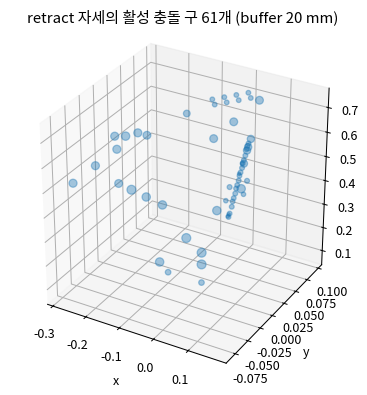

In [3]:
if HAS_CUROBO:
    kc = km20.kinematics_config
    idx2name = {v: k for k, v in kc.link_name_to_idx_map.items()}
    link_of = [idx2name[int(i)] for i in kc.link_sphere_idx_map.cpu().numpy()]
    cnt = Counter(l for l, a in zip(link_of, active) if a)
    for name, n in cnt.items():
        print('%-18s %2d개' % (name, n))

    # 실험 로그(evidence)에 저장된 구 반지름이 buffer 0.02 모델과 같은지 확인
    logged = np.load(EVIDENCE / 'R' / 'robot-spheres.npz')['spheres']
    print('\n로그 robot-spheres.npz 모양:', logged.shape, '(스텝, 구, xyz+반지름)')
    print('로그 반지름 = buffer 0.02 모델 반지름?', np.allclose(np.sort(logged[0, :, 3]), np.sort(sph20[active, 3])))

    fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
    s = sph20[active]
    ax.scatter(s[:, 0], s[:, 1], s[:, 2], s=(s[:, 3] * 400) ** 2 / 20, alpha=0.4)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_title('retract 자세의 활성 충돌 구 61개 (buffer 20 mm)'); ax.set_box_aspect((1, 1, 1))
    plt.show()
else:
    print('cuRobo/CUDA가 없어 건너뜀')

**결과 해석:**
- 손(`panda_hand`)과 팔꿈치 부근 링크(`panda_link5`)에 구가 가장 많다. 손은 모양이 복잡하고, link5는 길고 굵다.
- buffer를 0.004에서 0.02로 바꾸면 모든 구의 반지름이 정확히 0.016 m씩 커진다. 08에서 본 "반지름 = 실제 크기 + buffer" 그대로다.
- 실험 로그에 저장된 구도 buffer 0.02 모델과 같다. 그래서 로그의 간격(`original_surface_clearance_m`)은 **buffer 포함 구 표면** 기준이다. buffer를 뺀 간격과는 정확히 20 mm 차이 난다(12 노트).

## 2. 가변 dt horizon — 30칸으로 멀리 보기

### 문제
04에서 horizon이 짧으면 장애물 앞에서 멈추는 문제를 봤다. 멀리 보려면 두 가지 방법이 있다.
- **칸 수 $T$를 늘린다:** 계산량이 칸 수에 비례해서 늘어난다. 1초에 60번 계획해야 하는 로봇에게는 부담이다.
- **칸 간격 $\Delta t$를 키운다:** 바로 다음 순간도 거칠게 예측하게 된다. 그런데 실제로 실행하는 것은 계획의 **첫 입력**뿐이다(04). 가까운 미래가 가장 정확해야 한다.

### 아이디어
**가까운 미래는 촘촘하게, 먼 미래는 성기게** 나눈다. 칸 수는 30으로 그대로 두고 간격만 다르게 준다. cuRobo는 이렇게 한다.
- 앞 절반(15칸): 기본 간격 `base_dt`로 고정
- 뒤 절반(15칸): `base_dt`에서 `max_dt` = 0.04 s까지 일정하게 늘림

`common.dt_array`는 cuRobo의 이 규칙(`kinematic_model.py`의 `get_dt_array`)을 그대로 옮긴 것이다.

**예측해 보기:** `base_dt` = 0.02 s일 때 horizon 전체는 몇 초일까?

<details><summary>계산</summary>

앞 15칸: 15 × 0.02 = 0.30 s. 뒤 15칸: 0.02에서 0.04까지 고르게 늘어나는 15개의 평균은 0.03이니 15 × 0.03 = 0.45 s. 합 0.75 s. 모두 0.02로 나눴다면 0.6 s였다.
</details>

base_dt = 0.0200 s: 앞 15칸 0.300 s + 뒤 15칸 0.450 s = 전체 0.750 s
base_dt = 0.0167 s: 앞 15칸 0.250 s + 뒤 15칸 0.425 s = 전체 0.675 s

실험 로그: model_base_dt = 0.016667 s, physics_dt = 0.016667 s
실험 로그: trajectory_duration_s = 0.6750 s
dt_array(1/60)과 로그 trajectory_dt 최대 차이: 2.0e-09


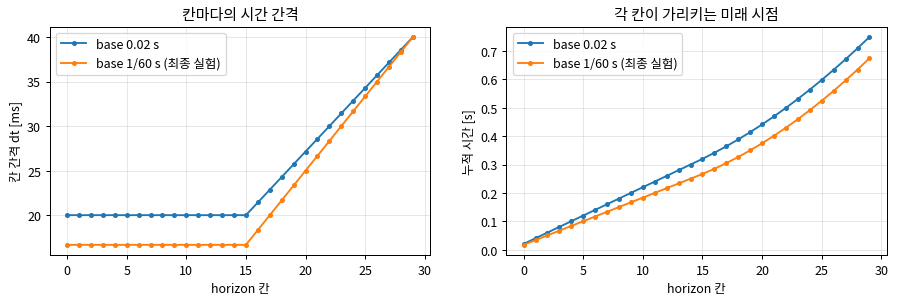

In [4]:
for base in [0.02, 1 / 60]:
    d = dt_array(base)
    print('base_dt = %.4f s: 앞 15칸 %.3f s + 뒤 15칸 %.3f s = 전체 %.3f s' % (base, d[:15].sum(), d[15:].sum(), d.sum()))

logged_cs = json.loads((EVIDENCE / 'HIGH' / 'control-settings.json').read_text())
print('\n실험 로그: model_base_dt = %.6f s, physics_dt = %.6f s' % (logged_cs['model_base_dt'], logged_cs['physics_dt']))
print('실험 로그: trajectory_duration_s = %.4f s' % logged_cs['trajectory_duration_s'])
print('dt_array(1/60)과 로그 trajectory_dt 최대 차이: %.1e' % np.abs(dt_array(1 / 60) - np.array(logged_cs['trajectory_dt'])).max())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
for base, lab in [(0.02, 'base 0.02 s'), (1 / 60, 'base 1/60 s (최종 실험)')]:
    d = dt_array(base)
    axs[0].plot(d * 1000, 'o-', ms=3, label=lab)
    axs[1].plot(np.cumsum(d), 'o-', ms=3, label=lab)
axs[0].set_xlabel('horizon 칸'); axs[0].set_ylabel('칸 간격 dt [ms]'); axs[0].legend(); axs[0].set_title('칸마다의 시간 간격')
axs[1].set_xlabel('horizon 칸'); axs[1].set_ylabel('누적 시간 [s]'); axs[1].legend(); axs[1].set_title('각 칸이 가리키는 미래 시점')
plt.show()

**결과 해석:**
- 같은 30칸으로 0.75 s(base 0.02) 또는 0.675 s(base 1/60)를 본다. 균일 간격이었다면 0.6 s, 0.5 s였다.
- 최종 실험은 MPC의 기본 간격을 Isaac Sim 물리 시뮬레이션 간격(1/60 s)과 같게 맞췄다. 그래서 horizon은 0.675 s다. 로그에 기록된 값과 계산이 일치한다.
- 처음 설정(`scene.json`의 `solver_dt` 0.02 s)에서는 MPC 한 칸(0.02 s)과 물리 한 스텝(1/60 s)이 달랐다. 최종 실험에서는 `--model-dt 1/60` 옵션으로 이 차이를 없앴다.

**직접 해보기:** `dt_array(1/60, max_dt=0.08)`과 `dt_array(1/60, base_ratio=1.0)`을 출력해 보자. horizon이 각각 몇 초가 될지 먼저 계산해 보자.
<details><summary>답</summary>

`max_dt=0.08`: 0.25 + 15 × (1/60 + 0.08)/2 ≈ 0.975 s. 뒤쪽 칸을 더 성기게 해서 같은 30칸으로 1초 가까이 본다. `base_ratio=1.0`: 30칸 모두 1/60 s라 0.5 s. 균일 간격과 같다.
</details>

**한 문장으로:** 가변 dt가 "멀리 보기"와 "첫 입력의 정확도"를 어떻게 함께 챙기는지 설명해 보자.

## 3. Isaac Sim 없이 cuRobo MPC 한 번 풀기

### 문제
08에서는 우리가 직접 MPPI 루프를 짰다. cuRobo에서는 `MpcSolver` 객체 하나가 이 일을 한다. 그 안에서 실제로 무슨 일이 일어나는지 보려면 어떻게 해야 할까?

### 아이디어
`MpcSolver`는 Isaac Sim 없이도 만들 수 있다. Isaac Sim은 "실제 로봇" 역할(물리 시뮬레이션)을 할 뿐이고, 계획은 cuRobo가 혼자 한다. 실험 장면을 다음처럼 단순하게 흉내 낸다.

| 항목 | 이 노트 | 실제 실험 |
|---|---|---|
| 장애물 | 손 크기 상자 하나(손 ROI 중심 근처) | 깊이 카메라 → nvblox 지도 + 손 패치 (10, 11 노트) |
| 시작 상태 | R 실험 로그 step 150의 실제 관절 각도·속도 | Isaac Sim에서 매 스텝 측정 |
| 목표 | Target B (`scene.json`) | 같음 |
| CUDA graph | 끔 (내부 함수를 직접 부르려고) | 켬 (빠르게 실행하려고) |

`MpcSolverConfig.load_from_robot_config`의 주요 인자는 다음과 같다.
- `use_mppi=True, use_lbfgs=False, use_es=False`: 최적화 방법으로 MPPI만 쓴다.
- `step_dt=1/60`: 2절의 `base_dt`
- `self_collision_check=True`: 로봇 구끼리 부딪히는 것도 비용에 넣는다.

In [5]:
if HAS_CUROBO:
    from curobo.geom.types import WorldConfig, Cuboid
    from curobo.types.math import Pose
    from curobo.types.state import JointState
    from curobo.rollout.rollout_base import Goal
    from curobo.rollout.arm_base import ArmBase
    from curobo.wrap.reacher.mpc import MpcSolver, MpcSolverConfig

    scene_cfg = json.loads((REPO / 'experiment' / 'scene.json').read_text())
    hand_box = Cuboid(name='hand_box', pose=[0.55, 0.0, 0.42, 1, 0, 0, 0], dims=[0.03, 0.12, 0.16])
    t0 = time.time()
    mpc = MpcSolver(MpcSolverConfig.load_from_robot_config(
        rcfg, WorldConfig(cuboid=[hand_box]), use_cuda_graph=False, use_mppi=True, use_lbfgs=False, use_es=False,
        store_rollouts=True, step_dt=1 / 60, self_collision_check=True))
    print('MpcSolver 생성 %.1f s' % (time.time() - t0))

    r150 = next(r for r in read_jsonl(EVIDENCE / 'R' / 'metrics.jsonl') if r['step'] == 150)
    print('R 로그 step 150: 목표 B로 이동 중, EE %s, 로그상 손 관측점과의 간격(buffer 포함) %.1f mm' % (
        np.round(r150['ee_position'], 3), 1000 * r150['original_surface_clearance_m']))
    js = JointState.from_position(ta.to_device([r150['actual_q'][:7]]), joint_names=mpc.joint_names)
    js.velocity[:] = ta.to_device([r150['actual_velocity']])
    goal = Goal(current_state=js, goal_state=js, goal_pose=Pose.from_list(scene_cfg['goals_wxyz'][1], ta))
    gb = mpc.setup_solve_single(goal, 1); mpc.update_goal(gb)
    for _ in range(3):                    # 몇 번 풀어 평균 입력열을 현재 상태에 맞춘다 (warm start)
        res = mpc.step(js, max_attempts=1)
    print('mpc.step 결과: 다음 명령 관절 위치 모양', tuple(res.js_action.position.shape), '| feasible:', res.metrics.feasible.cpu().tolist())
else:
    print('cuRobo/CUDA가 없어 건너뜀')

MpcSolver 생성 0.9 s
R 로그 step 150: 목표 B로 이동 중, EE [ 0.521 -0.361  0.405], 로그상 손 관측점과의 간격(buffer 포함) 146.7 mm
mpc.step 결과: 다음 명령 관절 위치 모양 (1, 9) | feasible: [[True]]


**결과 해석:** `mpc.step(js)` 한 번이 04의 "계획 → 첫 입력 꺼내기"에 해당한다. 안에서는 07에서 본 MPPI 갱신을 정해진 횟수만큼 반복한다. `js_action`은 다음에 보낼 관절 명령이다(그리퍼 손가락 2개 포함 9개).

`feasible`은 관절 한계 같은 **제약을 통과했는지**를 뜻한다. "아무것에도 부딪히지 않는다"는 뜻이 아니다. 이 차이는 11 노트에서 다시 본다.

## 4. 후보 400개 들여다보기

### 문제
`mpc.step` 안에서 만들어지는 후보 400개와 그 비용을 직접 볼 수 있을까?

### 아이디어
`MpcSolver` 안의 MPPI 최적화기(`optimizers[0]`)에서 후보 입력열을 뽑고, rollout 함수(`rollout_fn`)를 직접 부른다. 08과 이름만 다를 뿐 같은 흐름이다.

| 08 (2관절 팔, numpy) | cuRobo (Franka) |
|---|---|
| 각가속도 후보 `U[K, T, 2]` | `act_seq[400, 30, 7]` |
| `point_rollout` → 관절 각도 `[K, T+1, 2]` | 관절 상태 `[400, 30, 7]` |
| `fk_tip` → 손끝 `[K, T+1, 2]` | EE 위치 `[400, 30, 3]` |
| `sphere_centers` → 구 8개 | 충돌 구 `[400, 30, 65, 4]` |
| `arm_cost` → 시점별 비용 합 | `costs[400, 30]` (시점별), 합은 MPPI가 계산 |

In [6]:
if HAS_CUROBO:
    opt = mpc.solver.optimizers[0]
    ro = opt.rollout_fn
    print('최적화기:', type(opt).__name__, '| rollout:', type(ro).__name__)
    act = opt.sample_actions(opt.mean_action)            # 평균 주변 후보 [400, 30, 7]
    traj = ro.rollout_fn(act)                            # rollout + FK + 충돌 구 + 비용
    st = traj.state
    print('가속도 후보 act_seq ', tuple(act.shape))
    print('관절 위치 예측      ', tuple(st.state_seq.position.shape))
    print('EE 위치 예측        ', tuple(st.ee_pos_seq.shape))
    print('충돌 구 예측        ', tuple(st.robot_spheres.shape), '(마지막 축 = x, y, z, 반지름)')
    print('시점별 비용 costs   ', tuple(traj.costs.shape))
    print('horizon 전체 시간    %.3f s' % float(ro.dynamics_model.traj_dt.sum()))
else:
    print('cuRobo/CUDA가 없어 건너뜀')

최적화기: ParallelMPPI | rollout: ArmReacher
가속도 후보 act_seq  (400, 30, 7)
관절 위치 예측       (400, 30, 7)
EE 위치 예측         (400, 30, 3)
충돌 구 예측         (400, 30, 65, 4) (마지막 축 = x, y, z, 반지름)
시점별 비용 costs    (400, 30)
horizon 전체 시간    0.675 s


### 비용 항 나눠 보기

`costs[400, 30]`은 여러 비용 항을 더한 값이다. 02에서 배운 "항의 합" 구조 그대로다. cuRobo의 기본 비용 함수(`ArmBase.cost_fn`)는 항 목록을 이 순서로 만든다.

| 항 | 쉬운 말 |
|---|---|
| bound | 관절 각도·속도·가속도가 한계에 가까워지면 커진다 |
| stop | 너무 빨라서 남은 horizon 안에 멈출 수 없으면 커진다 |
| self_collision | 로봇의 구끼리 겹치면 커진다 |
| env_collision | 로봇 구가 환경(여기서는 상자)과 가까우면 커진다 (η 비용) |
| pose 목표 | EE가 목표 위치·방향에서 멀면 커진다 (항 목록 뒤에 추가됨) |

아래 셀은 앞의 네 항을 따로 계산하고, 총비용에서 이 넷을 뺀 나머지를 "pose 목표 등"으로 본다. 각 항은 02~06처럼 시점마다 $\gamma^t$ (γ = 0.98)를 곱해 더했다.

**예측해 보기:** 지금 로봇은 상자에서 떨어져 있다(로그 간격 약 147 mm). 그렇다면 400개 후보 중 환경 충돌 비용이 생기는 후보는 몇 개쯤일까?

In [7]:
if HAS_CUROBO:
    terms = ArmBase.cost_fn(ro, st, act, return_list=True)
    names = ['bound', 'stop', 'self_collision', 'env_collision']
    parts = {n: c.detach().cpu().numpy() for n, c in zip(names, terms)}
    total = traj.costs.cpu().numpy()
    parts['pose 목표 등'] = total - sum(parts.values())
    gamma_seq = 0.98 ** np.arange(30)
    print('항별 할인 합 (후보 400개 중 중앙값 / 최대):')
    for n, c in parts.items():
        Sx = (c * gamma_seq).sum(1)
        print('  %-15s 중앙값 %10.1f   최대 %10.1f' % (n, np.median(Sx), Sx.max()))
    S_tot = (total * gamma_seq).sum(1)
    hit = (parts['env_collision'] > 0).any(1)
    print('\n환경(상자) 충돌 비용이 생긴 후보: %d / 400' % hit.sum())
    print('총비용이 가장 낮은 후보 #%d: 충돌 비용 %s' % (S_tot.argmin(), '있음' if hit[S_tot.argmin()] else '없음'))

    # buffer 포함 구 표면 ↔ 상자(축 정렬) 간격: 첫 예측 시점과 horizon 전체 최소
    s = st.robot_spheres.cpu().numpy()
    lo = np.array(hand_box.pose[:3]) - np.array(hand_box.dims) / 2
    hi = np.array(hand_box.pose[:3]) + np.array(hand_box.dims) / 2
    gap = np.linalg.norm(np.maximum(0, np.maximum(lo - s[..., :3], s[..., :3] - hi)), axis=-1) - s[..., 3]
    gap[s[..., 3] <= 0] = np.inf
    print('구-상자 간격: 첫 예측 시점 최소 %.1f mm, horizon 전체 최소 %.1f mm (η = 25 mm)' % (
        1000 * gap[:, 0].min(), 1000 * gap.min()))
else:
    print('cuRobo/CUDA가 없어 건너뜀')

항별 할인 합 (후보 400개 중 중앙값 / 최대):
  bound           중앙값     1284.0   최대     2007.9
  stop            중앙값     8477.7   최대     9077.4
  self_collision  중앙값        0.0   최대        0.0
  env_collision   중앙값    34425.2   최대   598856.4
  pose 목표 등       중앙값   117604.1   최대   119971.3

환경(상자) 충돌 비용이 생긴 후보: 400 / 400
총비용이 가장 낮은 후보 #248: 충돌 비용 있음
구-상자 간격: 첫 예측 시점 최소 82.7 mm, horizon 전체 최소 -61.9 mm (η = 25 mm)


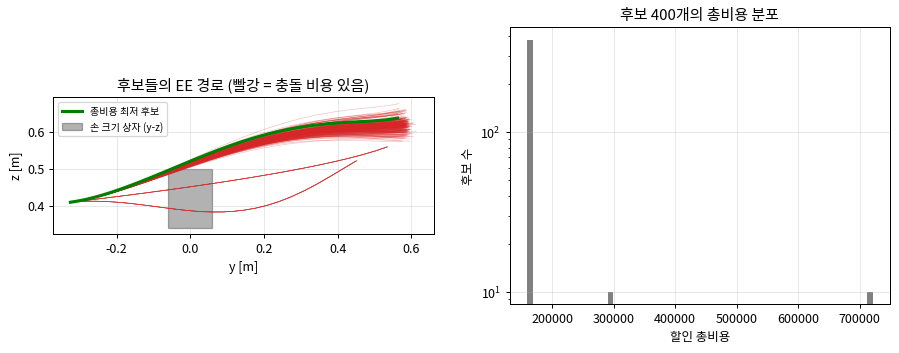

In [8]:
if HAS_CUROBO:
    ee = st.ee_pos_seq.cpu().numpy()
    order = np.argsort(S_tot)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for i in order[::-1][:300]:
        axs[0].plot(ee[i, :, 1], ee[i, :, 2], color='tab:red' if hit[i] else 'tab:blue', lw=0.5, alpha=0.3)
    axs[0].plot(ee[order[0], :, 1], ee[order[0], :, 2], 'g-', lw=2.5, label='총비용 최저 후보')
    axs[0].add_patch(plt.Rectangle((-0.06, 0.34), 0.12, 0.16, color='k', alpha=0.3, label='손 크기 상자 (y-z)'))
    axs[0].set_xlabel('y [m]'); axs[0].set_ylabel('z [m]'); axs[0].legend(fontsize=8); axs[0].set_aspect('equal')
    axs[0].set_title('후보들의 EE 경로 (빨강 = 충돌 비용 있음)')
    axs[1].hist(S_tot, bins=60, color='gray'); axs[1].set_yscale('log')
    axs[1].set_xlabel('할인 총비용'); axs[1].set_ylabel('후보 수'); axs[1].set_title('후보 400개의 총비용 분포')
    plt.show()
else:
    print('cuRobo/CUDA가 없어 건너뜀')

**결과 해석:**
- 지금 시점에서는 상자와 떨어져 있다(첫 예측 시점 간격이 η보다 크다). 그런데 B로 가는 후보들은 0.675 s 예측 안에서 **모두** 상자 근처를 지나간다(horizon 전체 최소 간격이 음수). 그래서 400개 **전부**에 환경 충돌 비용이 붙는다.
- 총비용이 가장 낮은 후보도 충돌 비용을 안고 있다. 06에서 본 soft cost의 성질 그대로다. 모든 후보가 비싸면 MPPI는 **그중 덜 나쁜 것**을 고른다. 충돌 비용은 후보를 지우는 금지 규칙이 아니라 점수일 뿐이다.
- 이 장면에서는 pose 목표 항이 충돌 항보다 크다. 어떤 후보가 뽑힐지는 두 항의 절충으로 정해진다. 가중치(w) 숫자만 보고 행동을 단정할 수 없는 이유다. 실제 크기는 오차·겹친 구 수·시점 누적에 따라 달라진다.
- 이 상자는 손을 대충 흉내 낸 것이다. 실제 실험의 지도·손 패치와 다르므로 수치를 실험 결과와 비교하지는 않는다.

## 5. cuRobo의 비용 설정

### 문제
4절의 비용 항들은 각각 얼마의 가중치로 더해질까? 이 값들은 어디에 있을까?

### 아이디어
cuRobo MPPI의 설정 파일 `particle_mpc.yml`의 `cost` 부분에 있다. 07에서 `mppi` 부분(샘플 수, β, 분산 갱신 등)을 봤다면, 여기는 "무엇에 몇 점을 매기나"다. 파일을 직접 읽어 출력한다.

In [9]:
cfg_file = CUROBO / 'src/curobo/content/configs/task/particle_mpc.yml'
cost_cfg = load_yaml(cfg_file)['cost']
show = {
    'pose_cfg': ['weight', 'terminal'],
    'bound_cfg': ['weight', 'activation_distance'],
    'stop_cfg': ['weight', 'max_nlimit'],
    'self_collision_cfg': ['weight'],
    'primitive_collision_cfg': ['weight', 'activation_distance', 'use_sweep', 'sweep_steps'],
}
for k, keys in show.items():
    print('%-24s ' % k + ', '.join(f'{kk}={cost_cfg[k][kk]}' for kk in keys))

pose_cfg                 weight=[60, 300.0, 20, 20], terminal=True
bound_cfg                weight=[5000.0, 5000.0, 5000.0, 0.0], activation_distance=[0.1, 0.1, 0.1, 0.1]
stop_cfg                 weight=100.0, max_nlimit=0.25
self_collision_cfg       weight=50000.0
primitive_collision_cfg  weight=100000.0, activation_distance=0.025, use_sweep=True, sweep_steps=4


| 설정 | 값 | 뜻 |
|---|---|---|
| `pose_cfg.weight` | [60, 300, 20, 20] | EE 목표 추종. 방향·위치 오차와 그 시점별 항에 대한 가중치 묶음 |
| `bound_cfg.weight` | 5000 (위치·속도·가속도) | 관절 한계 근처 벌점. `activation_distance`(0.1)는 한계에 얼마나 가까워졌을 때부터 비용을 켤지 정한다 |
| `stop_cfg.weight` | 100 | horizon 안에 못 멈출 만큼 빠른 속도에 벌점 |
| `self_collision_cfg.weight` | 50000 | 로봇 구끼리 겹침 |
| `primitive_collision_cfg.weight` | 100000 | 환경 충돌. **η = 0.025 m**(08의 η 비용식) |
| `use_sweep`, `sweep_steps` 4 | True | 두 예측 시점 사이도 4등분해 검사한다. 빠르게 지나가며 장애물을 "건너뛰는" 것을 막는다 |

충돌 가중치(10만)가 목표 가중치(수십~수백)보다 훨씬 크지만, 4절에서 본 것처럼 실제로는 pose 항이 더 클 수도 있다. 비용은 **가중치 × 오차의 크기 × 시점 수**이기 때문이다.

## 핵심 정리

- cuRobo는 08에서 numpy로 한 FK·충돌 구·η 비용·MPPI를 7관절 Franka에 대해 GPU로 계산한다.
- Franka 충돌 구는 배열 65칸 중 **활성 61개**다. buffer(기본 0.004 m, 이 프로젝트 0.02 m)는 모든 구 반지름에 더해진다.
- **가변 dt horizon:** 앞 15칸은 촘촘하게, 뒤 15칸은 0.04 s까지 성기게 나눈다. 30칸으로 0.75 s(base 0.02) 또는 0.675 s(base 1/60, 최종 실험)를 본다.
- `act_seq[400, 30, 7]` → 관절 상태 → EE·충돌 구 `[400, 30, 65, 4]` → `costs[400, 30]`. 비용은 bound, stop, self, env 충돌, pose 항의 합이다.
- 충돌 비용은 soft cost다. 모든 후보가 비싸면 덜 나쁜 후보가 뽑힌다. `feasible`은 비충돌을 뜻하지 않는다.

## 확인 문제

<details><summary>1. base_dt = 1/60 s일 때 horizon 전체 시간을 계산 과정과 함께 말해 보자.</summary>

앞 15칸: 15 × 1/60 = 0.25 s. 뒤 15칸: 1/60(≈0.0167)에서 0.04까지 고르게 늘어나는 15개, 평균 ≈ 0.0283 → 약 0.425 s. 합 0.675 s.
</details>

<details><summary>2. buffer를 0.004에서 0.02로 바꾸면 로봇은 장애물에서 대체로 더 멀리 지나갈까? 이유는?</summary>

대체로 그렇다. 구가 16 mm씩 커져서 같은 실제 위치에서도 간격이 16 mm 작게 계산된다. 그래서 η 비용이 더 일찍, 더 크게 켜진다.
</details>

<details><summary>3. 후보 400개 모두에 충돌 비용이 있으면 MPPI는 무엇을 하나?</summary>

총비용을 비교해 그중 가장 덜 나쁜 후보(또는 가중평균)를 고른다. 충돌 비용은 금지 규칙이 아니라 점수라서, 후보가 지워지지 않는다.
</details>

<details><summary>4. 충돌 가중치가 100000이면 충돌 항이 항상 가장 큰 비용 항인가?</summary>

아니다. 비용은 가중치 × 오차 크기 × 시점 수다. 4절처럼 겹침이 얕거나 일부 시점에만 있으면, 목표에서 먼 동안 계속 쌓이는 pose 항이 더 클 수 있다.
</details>

## 실제 프로젝트에서는

| 이 노트 | 프로젝트 코드 |
|---|---|
| buffer 0.02 | `experiment/hand_experiment.py:90` `collision_sphere_buffer=.02` |
| `MpcSolverConfig.load_from_robot_config(..., use_mppi=True, ...)` | `hand_experiment.py:100` (CUDA graph 켬, 충돌 세계는 nvblox `BLOX`) |
| `step_dt=1/60` | `scripts/replay.sh`의 `--model-dt 0.016666666666666666` |
| `mpc.step(js)` | `hand_experiment.py:298`, 매 물리 스텝마다 호출 |
| 손 크기 상자 | 실제로는 깊이 카메라 지도(10)와 손 관측 패치 비용(11) |
| 가변 dt 규칙 | `~/curobo/src/curobo/rollout/dynamics_model/kinematic_model.py` `get_dt_array` |

## 다음 노트

[10 · 로봇은 세상을 어떻게 보나](10_perception_map.ipynb): 이 노트에서는 장애물을 상자로 직접 넣었다. 실제 실험에서는 깊이 카메라가 본 것을 지도로 만들어 충돌 비용에 쓴다. 그 과정을 배운다.